In [1]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/ranjit2027
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd/Downey mildew
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd/Fresh leaf
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd/Anthracnose
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd/Fusarium wilt
/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd/Mosaic virus


In [2]:
# =====================================================================================
# CELL 0.0 | STEP 0 — CONFIG: the ONLY place to edit paths / hyper-parameters
# =====================================================================================
import os

_WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./working")

class CFG:
    # ---------------- paths ----------------
    DATA_ROOT       = "/kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd"                                  # None -> auto-detect under /kaggle/input, or "/kaggle/input/<dataset-name>"
    WORK_DIR        = _WORK
    SEVERITY_CSV    = os.path.join(_WORK, "severity.csv")    # produced by Step 0A, consumed by Step 4
    CLAHE_DIR       = os.path.join(_WORK, "clahe_cache")     # produced by Step 0B (offline CLAHE cache)
    REPORT_DIR      = os.path.join(_WORK, "reports")         # Step 8 tables / figures
    LESION_MASK_DIR = None                                   # optional GT masks: <dir>/<class>/<image_stem>.png ; None -> Pointing Game skipped

    # ---------------- data ----------------
    CLASSES = ["Anthracnose", "Downey mildew", "Fresh leaf", "Fusarium wilt", "Mosaic virus"]
    EXPECTED_COUNTS = {"Anthracnose": 410, "Downey mildew": 570, "Fresh leaf": 551, "Fusarium wilt": 502, "Mosaic virus": 600}
    SEV_NAMES = ["Mild", "Moderate", "Severe"]
    NUM_CLASSES, NUM_SEV = 5, 3
    IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    # ---------------- Step 0A: severity labels ----------------
    SEG_SIZE = 448
    HSV_LOW, HSV_HIGH = (25, 40, 40), (95, 255, 255)         # OpenCV HSV green range
    MORPH_K = 5
    SEV_BOUNDS = (0.05, 0.25)                                # <0.05 Mild, <0.25 Moderate, else Severe
    FORCE_STEP0 = False                                      # True -> recompute severity.csv even if it exists

    # ---------------- Step 0B: CLAHE cache ----------------
    CLAHE_CLIP, CLAHE_TILE = 2.0, (8, 8)
    CACHE_SIZE, JPEG_QUALITY = 448, 98

    # ---------------- Step 1: dedup + folds ----------------
    PHASH_THRESHOLD = 4                                      # max Hamming distance (of 64 bits) to call two images near-duplicates
    SPLIT_SEED = 42                                          # fixed seed for the stratified folds
    N_FOLDS = 5
    FOLDS_TO_RUN = None                                      # None -> all folds
    VAL_FRAC = 0.10                                          # validation share of each training portion (early stopping)

    # ---------------- Steps 2-4: optimisation ----------------
    SEEDS = (42, 123, 2024)                                  # >= 3 fixed seeds
    MAX_EPOCHS, PATIENCE, WARMUP_EPOCHS = 30, 10, 2
    LR, HEAD_LR_MULT, WEIGHT_DECAY, GRAD_CLIP = 1e-4, 10.0, 0.05, 1.0
    HEAD_DROPOUT, LABEL_SMOOTHING, FOCAL_GAMMA = 0.3, 0.05, 2.0
    LAMBDA_ORD, EDL_WEIGHT, EDL_ANNEAL_EPOCHS = 0.5, 1.0, 10
    NUM_WORKERS, PIN_MEMORY = 4, True
    RESTORE_BEST_IN_MEMORY = True                            # RAM-only best-weights restore after early stopping (never touches disk)
    VERBOSE_EPOCHS = False

    # ---------------- Step 3: abstention / calibration ----------------
    ABSTAIN_UNC, ABSTAIN_CONF = 0.30, 0.60                   # refer to expert if uncertainty > 0.30 OR max-prob < 0.60
    ABSTAIN_RATES = (0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50)
    ECE_BINS = 15

    # ---------------- Step 5: robustness ----------------
    RUN_ROBUSTNESS = True
    ROBUST_SEED = 1234
    CORRUPTIONS = {                                          # 5 severity levels each
        "lighting":  (0.75, 0.55, 0.40, 0.25, 0.15),         # brightness multiplier (darkening)
        "blur":      (1.0, 2.0, 3.0, 4.0, 6.0),              # Gaussian sigma (pixels)
        "noise":     (0.02, 0.05, 0.08, 0.12, 0.18),         # Gaussian noise std (on [0,1] scale)
        "occlusion": (0.05, 0.10, 0.20, 0.30, 0.40),         # fraction of image area covered by a black square
    }

    # ---------------- Step 6: XAI ----------------
    RUN_XAI = True
    XAI_N_IMAGES, XAI_STEPS, XAI_BLUR_SIGMA = 16, 20, 10.0

    # ---------------- experiment selection ----------------
    RUN_MODELS = None                                        # None -> every model in MODEL_ZOO, or a list of keys
    PROPOSED = "BG-EDLNet-ConvNeXt"
    QUICK_TEST = False                                       # True -> 1 seed, 1 fold, 2 epochs (smoke test)

In [3]:
# =====================================================================================
# CELL 0.1 | STEP 0 — Imports, device, reproducibility, DataLoader context
# =====================================================================================
# Optional (Kaggle, internet on):  !pip install -U timm albumentations scipy scikit-learn tqdm pandas matplotlib
import gc, math, time, random, warnings
import multiprocessing as mp
from collections import OrderedDict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import StratifiedKFold, train_test_split
from scipy import stats
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")

if CFG.QUICK_TEST:
    CFG.SEEDS, CFG.FOLDS_TO_RUN = (42,), (0,)
    CFG.MAX_EPOCHS, CFG.PATIENCE, CFG.WARMUP_EPOCHS, CFG.EDL_ANNEAL_EPOCHS = 2, 2, 1, 2
    CFG.XAI_N_IMAGES = 4

for _d in (CFG.WORK_DIR, CFG.CLAHE_DIR, CFG.REPORT_DIR):
    os.makedirs(_d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
MP_CTX = "fork" if "fork" in mp.get_all_start_methods() else None   # notebook-safe workers (Python 3.14 defaults to forkserver)
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

MEAN_T = torch.tensor(CFG.IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(CFG.IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)
MEAN_C, STD_C = MEAN_T.cpu(), STD_T.cpu()

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CFG.SPLIT_SEED)
print(f"torch {torch.__version__} | timm {timm.__version__} | opencv {cv2.__version__} | numpy {np.__version__} | "
      f"albumentations {A.__version__} | device {DEVICE} | AMP {USE_AMP}")

torch 2.10.0+cu128 | timm 1.0.26 | opencv 4.13.0 | numpy 2.0.2 | albumentations 2.0.8 | device cuda | AMP True


In [4]:
# =====================================================================================
# CELL 0.2 | STEP 0 — Locate the dataset and index every image (folder-per-class)
# =====================================================================================
def _norm(s: str) -> str:
    return s.lower().replace("-", "_").replace(" ", "_")

def find_dataset_root() -> str:
    want = {_norm(c) for c in CFG.CLASSES}
    top = CFG.DATA_ROOT if CFG.DATA_ROOT else "/kaggle/input"
    for cur, dirs, _ in os.walk(top):
        if want.issubset({_norm(d) for d in dirs}):
            return cur
        if cur[len(top):].count(os.sep) >= 4:
            dirs[:] = []
    raise FileNotFoundError(f"No folder containing the class folders {CFG.CLASSES} found under {top}. Set CFG.DATA_ROOT.")

DATA_ROOT = find_dataset_root()
_norm2cls = {_norm(c): c for c in CFG.CLASSES}
CLASS_DIR = {_norm2cls[_norm(d)]: d for d in os.listdir(DATA_ROOT)
             if os.path.isdir(os.path.join(DATA_ROOT, d)) and _norm(d) in _norm2cls}

records = []
for ci, cls in enumerate(CFG.CLASSES):
    cdir = os.path.join(DATA_ROOT, CLASS_DIR[cls])
    for fn in sorted(os.listdir(cdir)):
        if fn.lower().endswith(CFG.IMG_EXTS):
            records.append((os.path.join(cdir, fn), cls, ci))
DF_ALL = pd.DataFrame(records, columns=["image_path", "disease_class", "label"])

print("Dataset root:", DATA_ROOT)
counts = DF_ALL.disease_class.value_counts().reindex(CFG.CLASSES)
for c in CFG.CLASSES:
    flag = "" if counts[c] == CFG.EXPECTED_COUNTS[c] else f"  <-- expected {CFG.EXPECTED_COUNTS[c]}"
    print(f"  {c:<14} {counts[c]:>4}{flag}")
print("Total images:", len(DF_ALL))

Dataset root: /kaggle/input/datasets/ranjit2027/bitter-gourd-dataset/Bitter Gourd
  Anthracnose     410
  Downey mildew   570
  Fresh leaf      551
  Fusarium wilt   502
  Mosaic virus    600
Total images: 2633


In [5]:
# =====================================================================================
# CELL 0.3-BASE | STEP 0A — image reader used by Cells 0.3-QC / 0.3-GRID / 0.3-FIX / 0.4
# =====================================================================================
def read_resized(path: str, size: int):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    return None if img is None else cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

                 q10    q25  median    q75    q90    q99
Anthracnose    0.041  0.055   0.073  0.100  0.139  0.226
Downey mildew  0.057  0.072   0.090  0.115  0.143  0.165
Fresh leaf     0.032  0.041   0.052  0.064  0.081  0.207
Fusarium wilt  0.058  0.083   0.123  0.194  0.269  0.361
Mosaic virus   0.104  0.130   0.160  0.215  0.264  0.309


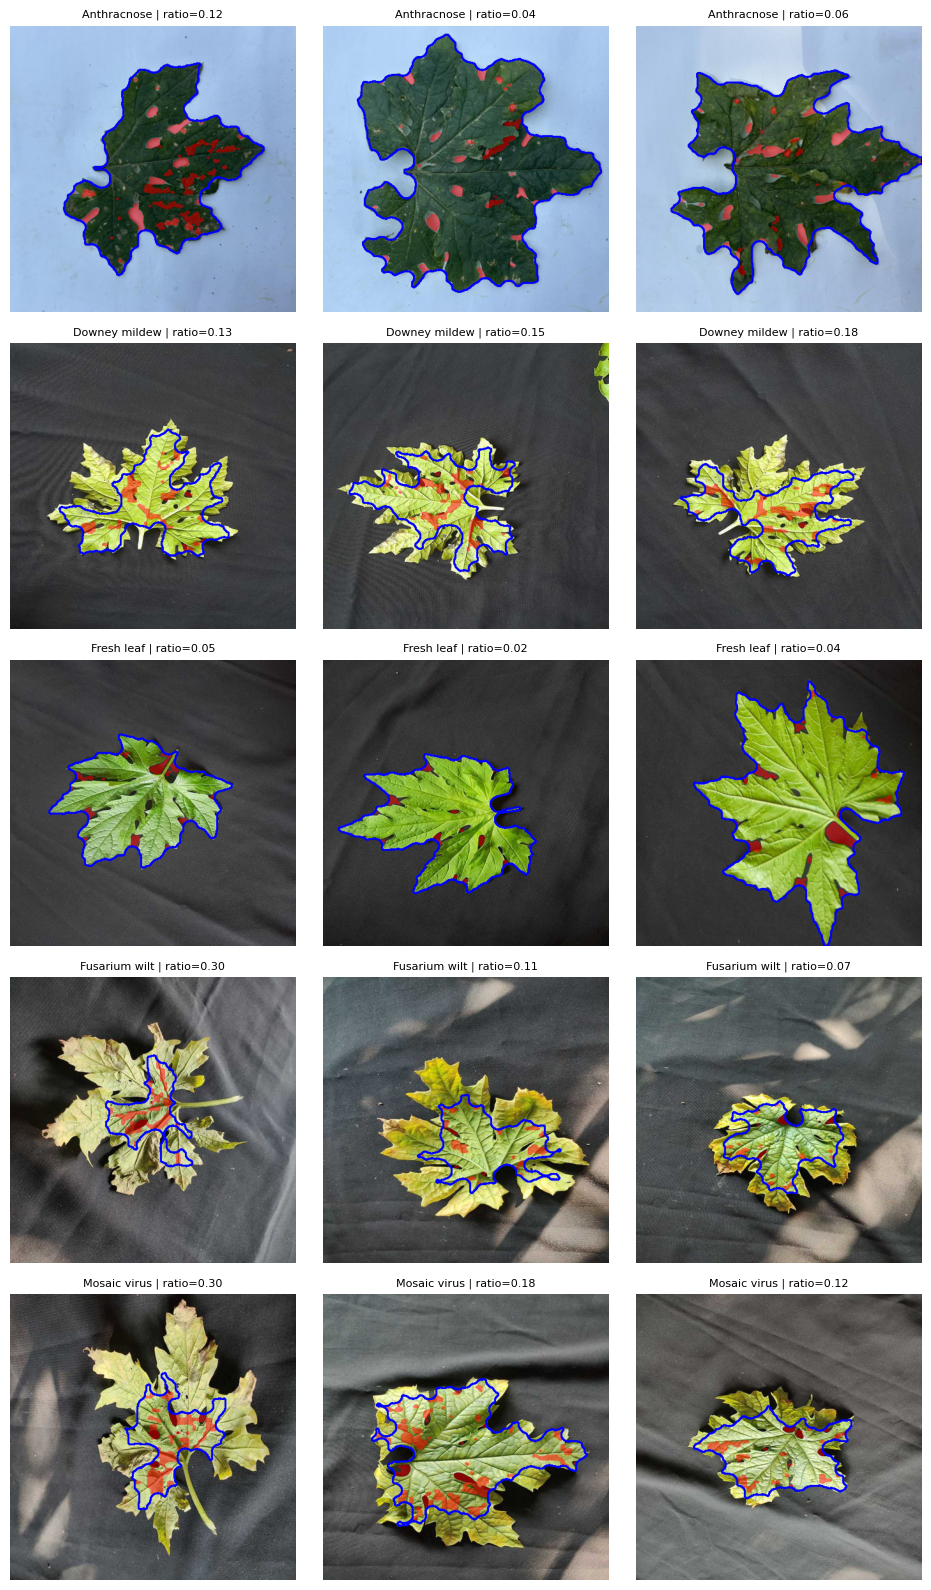

In [6]:
# =====================================================================================
# CELL 0.3-QC | STEP 0A — Recalibrate segmentation, inspect ratio quantiles + overlays (does NOT touch severity.csv)
# =====================================================================================
CFG.HSV_LOW, CFG.HSV_HIGH = (35, 40, 40), (85, 255, 255)   # yellow (H<35) is disease/chlorosis, not "green"
CFG.LEAF_CLOSE_K = 21                                       # fills margin notches of the leaf silhouette

def segment_leaf_and_lesion(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, np.array(CFG.HSV_LOW, np.uint8), np.array(CFG.HSV_HIGH, np.uint8))
    k_small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CFG.MORPH_K, CFG.MORPH_K))
    k_big = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CFG.LEAF_CLOSE_K, CFG.LEAF_CLOSE_K))
    green_c = cv2.morphologyEx(green, cv2.MORPH_OPEN, k_small)
    green_c = cv2.morphologyEx(green_c, cv2.MORPH_CLOSE, k_big)
    contours = cv2.findContours(green_c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    leaf = np.zeros_like(green)
    if len(contours) > 0:
        cv2.drawContours(leaf, [max(contours, key=cv2.contourArea)], -1, 255, -1)
    lesion = cv2.bitwise_and(cv2.bitwise_not(green), leaf)
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_OPEN, k_small)
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_CLOSE, k_small)
    return leaf, cv2.bitwise_and(lesion, leaf)

def ratio_quantiles(n_per_class=80, seed=0):
    rng, out = np.random.default_rng(seed), {}
    for cls in CFG.CLASSES:
        sub = DF_ALL[DF_ALL.disease_class == cls]
        vals = []
        for i in rng.choice(len(sub), min(n_per_class, len(sub)), replace=False):
            leaf, lesion = segment_leaf_and_lesion(read_resized(sub.iloc[i].image_path, CFG.SEG_SIZE))
            vals.append((lesion > 0).sum() / max((leaf > 0).sum(), 1))
        out[cls] = np.quantile(vals, [0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
    print(pd.DataFrame(out, index=["q10", "q25", "median", "q75", "q90", "q99"]).T.round(3).to_string())

def qc_overlay(n_per_class=3, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(CFG.CLASSES), n_per_class, figsize=(3.2 * n_per_class, 3.2 * len(CFG.CLASSES)))
    for r_i, cls in enumerate(CFG.CLASSES):
        sub = DF_ALL[DF_ALL.disease_class == cls]
        for c_i, i in enumerate(rng.choice(len(sub), n_per_class, replace=False)):
            img = read_resized(sub.iloc[i].image_path, CFG.SEG_SIZE)
            leaf, lesion = segment_leaf_and_lesion(img)
            vis = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            m = lesion > 0
            vis[m] = (0.5 * vis[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)        # lesion = red
            cv2.drawContours(vis, cv2.findContours(leaf, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2], -1, (0, 0, 255), 2)  # leaf outline = blue
            ax = axes[r_i, c_i]; ax.imshow(vis); ax.axis("off")
            ax.set_title(f"{cls} | ratio={m.sum() / max((leaf > 0).sum(), 1):.2f}", fontsize=8)
    plt.tight_layout(); plt.show()

ratio_quantiles()
qc_overlay()

In [7]:
# =====================================================================================
# CELL 0.3-GRID | STEP 0A — Calibrate HSV + morphology with Fresh leaf as negative control
#                 (place AFTER Cell 0.3-QC, BEFORE Cell 0.3-FIX)
# =====================================================================================
import itertools
CFG.LESION_OPEN_K = 5
HEALTHY_NAME = getattr(CFG, "HEALTHY_CLASS", "Fresh leaf")

def segment_leaf_and_lesion(img_bgr, hsv_low=None, hsv_high=None, open_k=None):
    hsv_low = hsv_low or CFG.HSV_LOW
    hsv_high = hsv_high or CFG.HSV_HIGH
    open_k = open_k or CFG.LESION_OPEN_K
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, np.array(hsv_low, np.uint8), np.array(hsv_high, np.uint8))
    ell = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    green_c = cv2.morphologyEx(green, cv2.MORPH_OPEN, ell(CFG.MORPH_K))
    green_c = cv2.morphologyEx(green_c, cv2.MORPH_CLOSE, ell(CFG.LEAF_CLOSE_K))
    contours = cv2.findContours(green_c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    leaf = np.zeros_like(green)
    if len(contours) > 0:
        cv2.drawContours(leaf, [max(contours, key=cv2.contourArea)], -1, 255, -1)
    lesion = cv2.bitwise_and(cv2.bitwise_not(green), leaf)
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_OPEN, ell(open_k))      # bigger kernel removes thin veins / speckle
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_CLOSE, ell(CFG.MORPH_K))
    return leaf, cv2.bitwise_and(lesion, leaf)

rng = np.random.default_rng(0)
sample = []
for cls in CFG.CLASSES:
    sub = DF_ALL[DF_ALL.disease_class == cls]
    for i in rng.choice(len(sub), min(40, len(sub)), replace=False):
        img = read_resized(sub.iloc[i].image_path, CFG.SEG_SIZE)
        if img is not None:
            sample.append((cls, img))

rows = []
for h_lo, s_min, o_k in tqdm(list(itertools.product((28, 32, 35), (20, 30, 40), (5, 9, 13))), desc="grid"):
    ratios = {c: [] for c in CFG.CLASSES}
    for cls, img in sample:
        leaf, lesion = segment_leaf_and_lesion(img, (h_lo, s_min, 40), CFG.HSV_HIGH, o_k)
        ratios[cls].append((lesion > 0).sum() / max((leaf > 0).sum(), 1))
    h = np.sort(np.array(ratios[HEALTHY_NAME]))
    d = np.concatenate([ratios[c] for c in CFG.CLASSES if c != HEALTHY_NAME])
    row = dict(h_lo=h_lo, s_min=s_min, open_k=o_k, healthy_med=np.median(h), healthy_q90=np.quantile(h, 0.9),
               auc=np.searchsorted(h, d).mean() / len(h))            # P(diseased ratio > healthy ratio)
    row.update({f"med_{c[:6]}": np.median(ratios[c]) for c in CFG.CLASSES if c != HEALTHY_NAME})
    rows.append(row)

GRID = pd.DataFrame(rows).sort_values("auc", ascending=False)
print(GRID.round(3).to_string(index=False))

ok = GRID[GRID.healthy_q90 <= 0.05]
best = (ok if len(ok) else GRID).iloc[0]
CFG.HSV_LOW = (int(best.h_lo), int(best.s_min), 40)
CFG.LESION_OPEN_K = int(best.open_k)
print("\nSelected -> HSV_LOW", CFG.HSV_LOW, "| LESION_OPEN_K", CFG.LESION_OPEN_K,
      "| healthy q90 <= 0.05" if len(ok) else "| WARNING: no setting has healthy q90 <= 0.05")
ratio_quantiles()

grid:   0%|          | 0/27 [00:00<?, ?it/s]

 h_lo  s_min  open_k  healthy_med  healthy_q90   auc  med_Anthra  med_Downey  med_Fusari  med_Mosaic
   32     20       5        0.037        0.051 0.927       0.066       0.064       0.101       0.110
   32     30       5        0.039        0.051 0.900       0.067       0.056       0.101       0.086
   32     20       9        0.015        0.026 0.895       0.038       0.025       0.048       0.050
   32     40       5        0.041        0.053 0.893       0.072       0.056       0.100       0.088
   35     20       5        0.041        0.089 0.886       0.067       0.099       0.119       0.159
   35     20       9        0.013        0.042 0.883       0.041       0.049       0.053       0.073
   28     20       5        0.033        0.045 0.879       0.060       0.047       0.086       0.081
   35     30       5        0.044        0.086 0.873       0.071       0.094       0.115       0.157
   35     40       5        0.047        0.091 0.870       0.073       0.093       0.110   

In [8]:
# =====================================================================================
# CELL 0.3-FIX | STEP 0A — Rebuild severity.csv: recalibrated segmentation + automatic bin check
#                (place AFTER Cell 0.3-QC, BEFORE Cell 1.0)
# =====================================================================================
assert hasattr(CFG, "LESION_OPEN_K"), "Run Cell 0.3-QC and 0.3-GRID first!"
CFG.HSV_LOW = (32, 20, 40)
CFG.LESION_OPEN_K = 5
MIN_GRADE_FRAC = 0.10       # every grade must hold >= 10% of the diseased images, else bins are re-derived from the data
HEALTHY_NAME = getattr(CFG, "HEALTHY_CLASS", "Fresh leaf")

def compute_lesion_ratios() -> pd.DataFrame:
    rows, bad = [], []
    for path, cls in tqdm(zip(DF_ALL.image_path, DF_ALL.disease_class), total=len(DF_ALL), desc="Step 0A ratios"):
        img = read_resized(path, CFG.SEG_SIZE)
        if img is None:
            bad.append(path); continue
        leaf, lesion = segment_leaf_and_lesion(img)                     # recalibrated version from Cell 0.3-QC
        leaf_area = torch.from_numpy(leaf > 0).sum().to(torch.float32)
        lesion_area = torch.from_numpy(lesion > 0).sum().to(torch.float32)
        rows.append((path, cls, (lesion_area / leaf_area.clamp_min(1.0)).clamp(0.0, 1.0).item()))   # PyTorch tensor math
    if bad:
        print(f"WARNING: {len(bad)} unreadable images skipped")
    return pd.DataFrame(rows, columns=["image_path", "disease_class", "lesion_ratio"])

def assign_severity(df: pd.DataFrame, bounds) -> pd.DataFrame:
    r = torch.tensor(df.lesion_ratio.values, dtype=torch.float32)
    idx = torch.bucketize(r, torch.tensor(bounds, dtype=torch.float32), right=True)
    out = df.copy()
    out["lesion_percent"] = out.lesion_ratio * 100.0
    out["severity"] = [CFG.SEV_NAMES[i] for i in idx.tolist()]
    return out[["image_path", "disease_class", "lesion_ratio", "lesion_percent", "severity"]]

RATIO_DF = compute_lesion_ratios()
diseased = RATIO_DF[RATIO_DF.disease_class != HEALTHY_NAME]

bounds = tuple(CFG.SEV_BOUNDS)                                             # spec thresholds first: 0.05 / 0.25
fracs = assign_severity(diseased, bounds).severity.value_counts(normalize=True).reindex(CFG.SEV_NAMES, fill_value=0.0)
print("Spec bins (0.05/0.25) on diseased images:", fracs.round(3).to_dict())

if (fracs < MIN_GRADE_FRAC).any():                                         # a grade is (almost) empty -> data-driven tertiles
    q = torch.quantile(torch.tensor(diseased.lesion_ratio.values, dtype=torch.float32), torch.tensor([1 / 3, 2 / 3]))
    bounds = tuple(float(v) for v in q)
    assert bounds[0] < bounds[1], f"tertile bounds not strictly increasing {bounds}: segmentation still does not separate lesion levels"
    print(f"Spec bins unbalanced -> data-driven tertile bounds (diseased images): {bounds[0]:.4f} / {bounds[1]:.4f}")
else:
    print("Spec bins are balanced enough -> keeping 0.05 / 0.25")

CFG.SEV_BOUNDS_USED = bounds                                               # report these thresholds in the paper
SEV_DF = assign_severity(RATIO_DF, bounds)                                 # Fresh leaf images use the same bounds (they land in Mild)
SEV_DF.to_csv(CFG.SEVERITY_CSV, index=False)
print(f"severity.csv rewritten -> {CFG.SEVERITY_CSV}  ({len(SEV_DF)} rows)")
print(pd.crosstab(SEV_DF.disease_class, SEV_DF.severity).reindex(columns=CFG.SEV_NAMES, fill_value=0))
print(CFG.HSV_LOW, CFG.LESION_OPEN_K, CFG.SEV_BOUNDS_USED)

Step 0A ratios:   0%|          | 0/2633 [00:00<?, ?it/s]

Spec bins (0.05/0.25) on diseased images: {'Mild': 0.116, 'Moderate': 0.874, 'Severe': 0.01}
Spec bins unbalanced -> data-driven tertile bounds (diseased images): 0.0703 / 0.1030
severity.csv rewritten -> /kaggle/working/severity.csv  (2633 rows)
severity       Mild  Moderate  Severe
disease_class                        
Anthracnose     188       107     115
Downey mildew   337       203      30
Fresh leaf      502        40       9
Fusarium wilt    85       160     257
Mosaic virus     84       224     292
(32, 20, 40) 5 (0.0702931359410286, 0.10299097746610641)


In [9]:
# =====================================================================================
# CELL 0.4 | STEP 0B — CLAHE applied OFFLINE once (L channel of LAB) and cached to disk.
#            Never executed inside the training loop.
# =====================================================================================
def cache_path_for(image_path: str, cls: str) -> str:
    return os.path.join(CFG.CLAHE_DIR, cls, os.path.basename(image_path).replace(".", "_") + ".jpg")

def apply_clahe_bgr(img_bgr: np.ndarray) -> np.ndarray:
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    clahe = cv2.createCLAHE(clipLimit=CFG.CLAHE_CLIP, tileGridSize=CFG.CLAHE_TILE)
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

n_new = 0
for path, cls in tqdm(zip(SEV_DF.image_path, SEV_DF.disease_class), total=len(SEV_DF), desc="Step 0B CLAHE cache"):
    out = cache_path_for(path, cls)
    if os.path.exists(out):
        continue
    img = read_resized(path, CFG.CACHE_SIZE)
    if img is None:
        continue
    os.makedirs(os.path.dirname(out), exist_ok=True)
    cv2.imwrite(out, apply_clahe_bgr(img), [cv2.IMWRITE_JPEG_QUALITY, CFG.JPEG_QUALITY])
    n_new += 1
print(f"CLAHE cache ready ({n_new} newly written) -> {CFG.CLAHE_DIR}")

Step 0B CLAHE cache:   0%|          | 0/2633 [00:00<?, ?it/s]

CLAHE cache ready (2633 newly written) -> /kaggle/working/clahe_cache


In [10]:
# =====================================================================================
# CELL 0.5 | STEP 0B — Image preprocessing: albumentations pipelines, Dataset, DataLoader factory
#            Train: random crop + flips + rotation + colour jitter. Test: resize + normalise only.
# =====================================================================================
def build_transform(size: int, train: bool, seed=None):
    norm = A.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD)
    if train:
        ops = [
            A.RandomResizedCrop(size=(size, size), scale=(0.65, 1.0), ratio=(0.85, 1.15), interpolation=cv2.INTER_AREA, p=1.0),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=30, border_mode=cv2.BORDER_REFLECT_101, p=0.5),
            A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.02, p=0.6),
            norm, ToTensorV2(),
        ]
    else:
        ops = [A.Resize(size, size, interpolation=cv2.INTER_AREA), norm, ToTensorV2()]
    try:
        return A.Compose(ops, seed=seed)
    except TypeError:
        return A.Compose(ops)

class LeafDataset(Dataset):
    def __init__(self, df: pd.DataFrame, size: int, train: bool):
        self.paths = df["cache_path"].tolist()
        self.y = df["label"].to_numpy(np.int64)
        self.s = df["sev_label"].to_numpy(np.int64)
        self.idx = df.index.to_numpy(np.int64)
        self.size, self.train = size, train
        self.tf = build_transform(size, train)

    def set_aug_seed(self, seed: int):
        self.tf = build_transform(self.size, self.train, seed=seed)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.imread(self.paths[i], cv2.IMREAD_COLOR)
        if img is None:
            raise RuntimeError(f"Cannot read cached image {self.paths[i]}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        x = self.tf(image=img)["image"]
        return x, int(self.y[i]), int(self.s[i]), int(self.idx[i])

def _worker_init(worker_id: int):
    seed = torch.initial_seed() % (2 ** 32)          # differs per worker AND per epoch
    random.seed(seed); np.random.seed(seed)
    info = torch.utils.data.get_worker_info()
    if info is not None:
        info.dataset.set_aug_seed(seed)

def make_loader(df_sub: pd.DataFrame, size: int, train: bool, batch_size: int, generator=None) -> DataLoader:
    kw = dict(batch_size=batch_size, shuffle=train, drop_last=train, num_workers=CFG.NUM_WORKERS,
              pin_memory=CFG.PIN_MEMORY, worker_init_fn=_worker_init, generator=generator)
    if CFG.NUM_WORKERS > 0 and MP_CTX is not None:
        kw["multiprocessing_context"] = MP_CTX
    return DataLoader(LeafDataset(df_sub, size, train), **kw)

In [11]:
# =====================================================================================
# CELL 1.0 | STEP 1 — Near-duplicate removal (perceptual hash, flip-invariant, within class)
#            followed by a stratified 5-fold split with a fixed seed
# =====================================================================================
def phash_variants(img_bgr: np.ndarray) -> np.ndarray:
    g = cv2.cvtColor(cv2.resize(img_bgr, (32, 32), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY).astype(np.float32)
    outs = []
    for v in (g, g[:, ::-1], g[::-1, :], g[::-1, ::-1]):          # original, h-flip, v-flip, 180° rotation
        d = cv2.dct(np.ascontiguousarray(v))[:8, :8].reshape(-1)
        outs.append(d > np.median(d))
    return np.stack(outs)                                          # (4, 64) bool

BASE_DF = DF_ALL[DF_ALL.image_path.isin(SEV_DF.image_path)].reset_index(drop=True)
hashes = []
for p in tqdm(BASE_DF.image_path, desc="Step 1 pHash"):
    img = cv2.imread(p, cv2.IMREAD_COLOR)
    hashes.append(phash_variants(img))
HV = np.stack(hashes).astype(np.float32) * 2.0 - 1.0               # (N, 4, 64) in {-1,+1}
dist = np.full((len(BASE_DF), len(BASE_DF)), 64.0, dtype=np.float32)
for v in range(HV.shape[1]):
    dist = np.minimum(dist, (64.0 - HV[:, 0, :] @ HV[:, v, :].T) / 2.0)   # Hamming distance

labels_np = BASE_DF.label.to_numpy()
close = dist <= CFG.PHASH_THRESHOLD
np.fill_diagonal(close, False)
cross = int((close & (labels_np[:, None] != labels_np[None, :])).sum() // 2)
if cross:
    print(f"NOTE: {cross} near-duplicate pairs span DIFFERENT classes (kept; inspect for label noise).")

keep = np.zeros(len(BASE_DF), dtype=bool)
for i in range(len(BASE_DF)):
    cand = keep & (labels_np == labels_np[i])
    if cand.any() and close[i, cand].any():
        continue
    keep[i] = True

DF_SPLIT = BASE_DF[keep].reset_index(drop=True)
DF_SPLIT["cache_path"] = [cache_path_for(p, c) for p, c in zip(DF_SPLIT.image_path, DF_SPLIT.disease_class)]
print(f"Near-duplicates removed: {int((~keep).sum())}  ({len(BASE_DF)} -> {len(DF_SPLIT)})")

skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SPLIT_SEED)
DF_SPLIT["fold"] = -1
for f, (_, te) in enumerate(skf.split(DF_SPLIT, DF_SPLIT.label)):
    DF_SPLIT.loc[te, "fold"] = f
print(pd.crosstab(DF_SPLIT.disease_class, DF_SPLIT.fold).reindex(CFG.CLASSES))

Step 1 pHash:   0%|          | 0/2633 [00:00<?, ?it/s]

NOTE: 134 near-duplicate pairs span DIFFERENT classes (kept; inspect for label noise).
Near-duplicates removed: 194  (2633 -> 2439)
fold             0    1    2    3    4
disease_class                         
Anthracnose     82   81   81   81   81
Downey mildew  108  108  108  108  108
Fresh leaf      98   99   99   99   99
Fusarium wilt   95   95   94   94   94
Mosaic virus   105  105  106  106  105


In [12]:
# =====================================================================================
# CELL 2.0 | STEP 2 — Backbones (ConvNeXt-T primary, Swin-T secondary, 5 baselines) from timm, ImageNet-pretrained
#            + model zoo describing the proposed model, ablations and baselines
# =====================================================================================
class CoralHead(nn.Module):
    """CORAL: one shared weight vector + (K-1) independent biases -> K-1 cumulative logits P(y > k)."""
    def __init__(self, in_dim: int, num_levels: int):
        super().__init__()
        self.fc = nn.Linear(in_dim, 1, bias=False)
        self.bias = nn.Parameter(torch.linspace(1.0, -1.0, num_levels - 1))
    def forward(self, x):
        return self.fc(x) + self.bias

class BGNet(nn.Module):
    def __init__(self, spec: dict, pretrained: bool = True):
        super().__init__()
        self.img_size = spec["img_size"]
        self.evidential, self.use_ordinal = spec["evidential"], spec["ordinal"]
        self.backbone = timm.create_model(spec["timm"], pretrained=pretrained, num_classes=0, **spec["kw"])
        self.backbone.eval()
        with torch.no_grad():                                        # probe output layout / feature width on CPU
            f, p = self.encode(torch.zeros(2, 3, self.img_size, self.img_size))
        self.feats_nhwc = (f.ndim == 4 and f.shape[-1] > f.shape[1])  # Swin returns NHWC feature maps
        feat_dim = p.shape[1]
        self.drop = nn.Dropout(CFG.HEAD_DROPOUT)
        self.cls_head = nn.Linear(feat_dim, CFG.NUM_CLASSES)
        nn.init.trunc_normal_(self.cls_head.weight, std=0.02); nn.init.zeros_(self.cls_head.bias)
        self.ord_head = CoralHead(feat_dim, CFG.NUM_SEV) if self.use_ordinal else None

    def encode(self, x):
        feats = self.backbone.forward_features(x)
        pooled = self.backbone.forward_head(feats, pre_logits=True)
        if pooled.ndim > 2:
            pooled = pooled.flatten(1)
        return feats, pooled

    def forward(self, x):
        _, pooled = self.encode(x)
        h = self.drop(pooled)
        out = {"logits": self.cls_head(h)}
        if self.ord_head is not None:
            out["ord_logits"] = self.ord_head(h)
        return out

def _spec(timm_name, img=224, bs=32, evid=False, ordn=False, **kw):
    return dict(timm=timm_name, img_size=img, batch=bs, evidential=evid, ordinal=ordn, kw=kw)

MODEL_ZOO = OrderedDict([
    ("BG-EDLNet-ConvNeXt", _spec("convnext_tiny", 224, 32, True, True, drop_path_rate=0.1)),
    ("BG-EDLNet-Swin",     _spec("swin_tiny_patch4_window7_224", 384, 16, True, True, drop_path_rate=0.1, img_size=384, window_size=12)),
    ("Abl-noEDL",          _spec("convnext_tiny", 224, 32, False, True, drop_path_rate=0.1)),     # softmax+focal, severity head ON
    ("Abl-noSeverity",     _spec("convnext_tiny", 224, 32, True, False, drop_path_rate=0.1)),     # EDL ON, severity head OFF
    ("ConvNeXt-plain",     _spec("convnext_tiny", 224, 32, False, False, drop_path_rate=0.1)),    # both OFF (also a baseline)
    ("ResNet50",           _spec("resnet50")),
    ("MobileNetV3-Large",  _spec("mobilenetv3_large_100")),
    ("EfficientNet-B0",    _spec("efficientnet_b0")),
    ("VGG16",              _spec("vgg16")),
    ("DenseNet121",        _spec("densenet121")),
])

def build_model(spec: dict) -> BGNet:
    try:
        return BGNet(spec)
    except Exception as e:
        if spec["timm"].startswith("swin"):        # e.g. relative-position-bias resize unsupported -> fall back to native 224
            warnings.warn(f"Swin-T @384 could not be built ({e}); falling back to 224x224 / window 7.")
            spec2 = dict(spec); spec2["img_size"] = 224; spec2["kw"] = {"drop_path_rate": 0.1}
            return BGNet(spec2)
        raise

def make_param_groups(model: BGNet):
    groups = []
    for is_head in (False, True):
        mods = ([model.cls_head] + ([model.ord_head] if model.ord_head is not None else [])) if is_head else [model.backbone]
        params = [p for m in mods for p in m.parameters() if p.requires_grad]
        lr = CFG.LR * (CFG.HEAD_LR_MULT if is_head else 1.0)
        groups.append({"params": [p for p in params if p.ndim > 1], "lr": lr, "weight_decay": CFG.WEIGHT_DECAY})
        groups.append({"params": [p for p in params if p.ndim <= 1], "lr": lr, "weight_decay": 0.0})
    return [g for g in groups if len(g["params"]) > 0]

In [13]:
# =====================================================================================
# CELL 2.1 | STEP 2 — Class-weighted Focal loss (imbalance handling) with light label smoothing
# =====================================================================================
def compute_class_weights(labels) -> torch.Tensor:
    counts = torch.bincount(torch.as_tensor(np.asarray(labels)), minlength=CFG.NUM_CLASSES).float()
    w = counts.sum() / (CFG.NUM_CLASSES * counts.clamp_min(1.0))       # inverse frequency
    return (w / w.mean()).to(DEVICE)

def focal_loss(logp: torch.Tensor, target: torch.Tensor, class_w: torch.Tensor, gamma: float, smoothing: float):
    K = logp.size(1)
    with torch.no_grad():
        t = torch.full_like(logp, smoothing / (K - 1))
        t.scatter_(1, target[:, None], 1.0 - smoothing)
    pt = logp.gather(1, target[:, None]).squeeze(1).exp()
    mod = (1.0 - pt).clamp_min(1e-6) ** gamma
    ce = -(t * logp).sum(1)
    w = class_w[target]
    return (w * mod * ce).sum() / w.sum()

In [14]:
# =====================================================================================
# CELL 3.0 | STEP 3 — Dirichlet evidential head: probabilities + uncertainty, EDL loss, abstention rule
# =====================================================================================
def probs_and_uncertainty(logits: torch.Tensor, evidential: bool):
    logits = logits.float()
    K = logits.size(1)
    if evidential:
        alpha = F.softplus(logits) + 1.0                 # Dirichlet parameters = evidence + 1
        S = alpha.sum(1, keepdim=True)
        return alpha / S, (K / S).squeeze(1)             # expected class probabilities, vacuity uncertainty u = K/S
    probs = F.softmax(logits, dim=1)
    return probs, 1.0 - probs.max(1).values              # softmax models: 1 - max-prob

def kl_dirichlet_uniform(alpha: torch.Tensor) -> torch.Tensor:
    K = alpha.size(1)
    S = alpha.sum(1, keepdim=True)
    ln_b = torch.lgamma(S) - torch.lgamma(alpha).sum(1, keepdim=True)
    ln_b_uni = -torch.lgamma(torch.tensor(float(K), device=alpha.device))
    dg = ((alpha - 1.0) * (torch.digamma(alpha) - torch.digamma(S))).sum(1, keepdim=True)
    return (dg + ln_b + ln_b_uni).squeeze(1)

def edl_loss(logits: torch.Tensor, target: torch.Tensor, epoch: int) -> torch.Tensor:
    """Sensoy et al. (2018): Bayes-risk squared error + annealed KL(Dir(alpha_tilde) || Dir(1))."""
    K = logits.size(1)
    y = F.one_hot(target, K).float()
    alpha = F.softplus(logits.float()) + 1.0
    S = alpha.sum(1, keepdim=True)
    p = alpha / S
    risk = ((y - p) ** 2).sum(1) + (p * (1.0 - p) / (S + 1.0)).sum(1)
    alpha_tilde = y + (1.0 - y) * alpha                  # remove evidence of the true class
    anneal = min(1.0, epoch / max(1, CFG.EDL_ANNEAL_EPOCHS))
    return (risk + anneal * kl_dirichlet_uniform(alpha_tilde)).mean()

def abstention_decision(probs: torch.Tensor, unc: torch.Tensor):
    """Returns (decision, refer_mask). decision == -1 means 'expert-refer'."""
    conf, pred = probs.max(1)
    refer = (unc > CFG.ABSTAIN_UNC) | (conf < CFG.ABSTAIN_CONF)
    decision = pred.clone()
    decision[refer] = -1
    return decision, refer

In [15]:
# =====================================================================================
# CELL 4.0 | STEP 4 — CORAL ordinal loss / decoding and the combined objective
#            Total loss = class-weighted focal + EDL + lambda * CORAL
# =====================================================================================
def coral_loss(ord_logits: torch.Tensor, sev: torch.Tensor, num_levels: int) -> torch.Tensor:
    levels = (sev[:, None] > torch.arange(num_levels - 1, device=sev.device)[None, :]).float()
    return F.binary_cross_entropy_with_logits(ord_logits.float(), levels, reduction="none").sum(1).mean()

def ord_decode(ord_logits: torch.Tensor) -> torch.Tensor:
    return (torch.sigmoid(ord_logits.float()) > 0.5).sum(1)           # predicted rank in {0,1,2}

def compute_total_loss(out: dict, y, sev, spec: dict, class_w, epoch: int) -> torch.Tensor:
    logits = out["logits"].float()
    if spec["evidential"]:
        probs, _ = probs_and_uncertainty(logits, True)
        logp = torch.log(probs.clamp_min(1e-8))
    else:
        logp = F.log_softmax(logits, dim=1)
    loss = focal_loss(logp, y, class_w, CFG.FOCAL_GAMMA, CFG.LABEL_SMOOTHING)
    if spec["evidential"]:
        loss = loss + CFG.EDL_WEIGHT * edl_loss(logits, y, epoch)
    if spec["ordinal"]:
        loss = loss + CFG.LAMBDA_ORD * coral_loss(out["ord_logits"], sev, CFG.NUM_SEV)
    return loss

In [16]:
# =====================================================================================
# CELL 4.1 | STEP 4/8 — Evaluation metrics in pure PyTorch (classification, severity, calibration, abstention)
# =====================================================================================
def confusion_matrix(y: torch.Tensor, pred: torch.Tensor, K: int) -> torch.Tensor:
    return torch.bincount(y * K + pred, minlength=K * K).view(K, K)

def prf_from_cm(cm: torch.Tensor):
    cm = cm.double()
    tp = cm.diag(); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    prec = tp / (tp + fp).clamp_min(1.0)
    rec = tp / (tp + fn).clamp_min(1.0)
    f1 = 2 * prec * rec / (prec + rec).clamp_min(1e-12)
    return prec, rec, f1

def ece_score(probs: torch.Tensor, y: torch.Tensor, n_bins: int = 15) -> float:
    conf, pred = probs.max(1)
    acc = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return float(ece)

def brier_score(probs: torch.Tensor, y: torch.Tensor) -> float:
    return ((probs - F.one_hot(y, probs.size(1)).float()) ** 2).sum(1).mean().item()

def quadratic_weighted_kappa(cm: torch.Tensor) -> float:
    cm = cm.double(); K = cm.size(0); n = cm.sum()
    idx = torch.arange(K, dtype=torch.float64)
    W = (idx[:, None] - idx[None, :]) ** 2 / float((K - 1) ** 2)
    E = torch.outer(cm.sum(1), cm.sum(0)) / n
    den = (W * E).sum()
    return float(1.0 - (W * cm).sum() / den) if den > 0 else 0.0

def compute_metrics(probs, unc, y, sev=None, sev_pred=None) -> dict:
    K = CFG.NUM_CLASSES
    pred = probs.argmax(1)
    cm = confusion_matrix(y, pred, K)
    prec, rec, f1 = prf_from_cm(cm)
    correct = (pred == y).float()
    m = dict(acc=correct.mean().item(), macro_f1=f1.mean().item(), macro_prec=prec.mean().item(), macro_rec=rec.mean().item(),
             ece=ece_score(probs, y, CFG.ECE_BINS), brier=brier_score(probs, y), cm=cm.numpy(), pred=pred.numpy())
    # abstention-rate vs accuracy (threshold-free: reject the most uncertain fraction)
    order = torch.argsort(unc)
    corr_sorted, n = correct[order], len(y)
    m["abst_curve"] = np.array([corr_sorted[:max(1, int(math.ceil((1 - r) * n)))].mean().item() for r in CFG.ABSTAIN_RATES])
    # fixed expert-refer rule
    _, refer = abstention_decision(probs, unc)
    kept = ~refer
    m["abst_rate"] = refer.float().mean().item()
    m["acc_retained"] = correct[kept].mean().item() if kept.any() else float("nan")
    m["acc_referred"] = correct[refer].mean().item() if refer.any() else float("nan")
    # ordinal severity metrics
    m.update(sev_mae=float("nan"), sev_qwk=float("nan"), sev_f1_mild=float("nan"), sev_f1_moderate=float("nan"), sev_f1_severe=float("nan"))
    if sev_pred is not None and sev is not None:
        cm_s = confusion_matrix(sev, sev_pred, CFG.NUM_SEV)
        _, _, f1s = prf_from_cm(cm_s)
        m.update(sev_mae=(sev_pred - sev).abs().float().mean().item(), sev_qwk=quadratic_weighted_kappa(cm_s),
                 sev_f1_mild=f1s[0].item(), sev_f1_moderate=f1s[1].item(), sev_f1_severe=f1s[2].item())
    return m

In [17]:
# =====================================================================================
# CELL 4.2 | STEP 4 — TRAINING CELL: load severity.csv, join by image_path, then the AMP training engine
#            (AdamW + warmup-cosine, grad clipping, early stopping patience=10, max 30 epochs, no checkpoints)
# =====================================================================================
SEV_CSV_DF = pd.read_csv(CFG.SEVERITY_CSV)                                   # <- Step 0A output
MASTER_DF = DF_SPLIT.merge(SEV_CSV_DF[["image_path", "lesion_ratio", "lesion_percent", "severity"]],
                           on="image_path", how="left", validate="one_to_one").reset_index(drop=True)
assert MASTER_DF["severity"].notna().all(), "severity.csv join failed: some images have no severity label"
MASTER_DF["sev_label"] = MASTER_DF["severity"].map({n: i for i, n in enumerate(CFG.SEV_NAMES)}).astype(int)
print(f"MASTER_DF: {len(MASTER_DF)} images | severity: {MASTER_DF.severity.value_counts().to_dict()}")

def get_fold_indices(df: pd.DataFrame, fold: int):
    te = df.index[df.fold == fold].to_numpy()
    rest = df[df.fold != fold]
    tr, va = train_test_split(rest.index.to_numpy(), test_size=CFG.VAL_FRAC, stratify=rest.label.values,
                              random_state=CFG.SPLIT_SEED + fold)
    return np.sort(tr), np.sort(va), te

def train_one_epoch(model, loader, optimizer, scheduler, scaler, spec, class_w, epoch):
    model.train()
    total, n = torch.zeros((), device=DEVICE), 0
    for x, y, s, _ in loader:
        x, y, s = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True), s.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        loss = compute_total_loss(out, y, s, spec, class_w, epoch)          # losses computed in fp32
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.detach() * x.size(0); n += x.size(0)
    return (total / max(n, 1)).item()

@torch.no_grad()
def predict_loader(model, loader, evidential: bool) -> dict:
    model.eval()
    P, U, Y, S, O = [], [], [], [], []
    for x, y, s, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        probs, unc = probs_and_uncertainty(out["logits"], evidential)
        P.append(probs.cpu()); U.append(unc.cpu()); Y.append(y); S.append(s)
        if "ord_logits" in out:
            O.append(ord_decode(out["ord_logits"]).cpu())
    return dict(probs=torch.cat(P), unc=torch.cat(U), y=torch.cat(Y), sev=torch.cat(S), sev_pred=torch.cat(O) if O else None)

@torch.no_grad()
def predict_tensors(model, X01: torch.Tensor, evidential: bool, batch: int = 64, transform=None) -> dict:
    """Inference on un-normalised [0,1] image tensors (optionally corrupted on-GPU)."""
    model.eval()
    P, U, O = [], [], []
    for i in range(0, X01.size(0), batch):
        xb = X01[i:i + batch].to(DEVICE, non_blocking=True).float()
        if transform is not None:
            xb = transform(xb, i)
        xb = (xb - MEAN_T) / STD_T
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        probs, unc = probs_and_uncertainty(out["logits"], evidential)
        P.append(probs.cpu()); U.append(unc.cpu())
        if "ord_logits" in out:
            O.append(ord_decode(out["ord_logits"]).cpu())
    return dict(probs=torch.cat(P), unc=torch.cat(U), sev_pred=torch.cat(O) if O else None)

def fit_model(model, spec, tr_loader, va_loader, class_w) -> dict:
    optimizer = torch.optim.AdamW(make_param_groups(model), betas=(0.9, 0.999), fused=(DEVICE.type == "cuda"))
    spe = len(tr_loader); total = CFG.MAX_EPOCHS * spe; warm = max(1, CFG.WARMUP_EPOCHS * spe)
    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(1, total - warm)
        return 0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * prog))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    best, best_epoch, bad, best_state = -1.0, -1, 0, None
    for epoch in range(CFG.MAX_EPOCHS):
        tr_loss = train_one_epoch(model, tr_loader, optimizer, scheduler, scaler, spec, class_w, epoch)
        v = predict_loader(model, va_loader, spec["evidential"])
        vm = compute_metrics(v["probs"], v["unc"], v["y"], v["sev"], v["sev_pred"])
        if CFG.VERBOSE_EPOCHS:
            print(f"    ep {epoch + 1:02d} | loss {tr_loss:.4f} | val acc {vm['acc']:.4f} f1 {vm['macro_f1']:.4f}")
        if vm["macro_f1"] > best + 1e-4:
            best, best_epoch, bad = vm["macro_f1"], epoch + 1, 0
            if CFG.RESTORE_BEST_IN_MEMORY:                                    # RAM-only copy, never written to disk
                best_state = {k: v_.detach().to("cpu", copy=True) for k, v_ in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG.PATIENCE:
                break
    if CFG.RESTORE_BEST_IN_MEMORY and best_state is not None:
        model.load_state_dict(best_state)
    del best_state
    return dict(epochs_run=epoch + 1, best_epoch=best_epoch, best_val_f1=best)

MASTER_DF: 2439 images | severity: {'Mild': 1107, 'Moderate': 692, 'Severe': 640}


In [18]:
# =====================================================================================
# CELL 5.0 | STEP 5 — Corruption-robustness: lighting, blur, noise, occlusion at 5 severity levels (all on GPU, pure PyTorch)
# =====================================================================================
def gaussian_blur(x: torch.Tensor, sigma: float) -> torch.Tensor:
    r = max(1, int(math.ceil(3 * sigma)))
    k = torch.arange(-r, r + 1, device=x.device, dtype=x.dtype)
    k = torch.exp(-(k ** 2) / (2 * sigma ** 2)); k = k / k.sum()
    C = x.shape[1]
    kh = k.view(1, 1, 1, -1).repeat(C, 1, 1, 1)
    kv = k.view(1, 1, -1, 1).repeat(C, 1, 1, 1)
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), kh, groups=C)
    return F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), kv, groups=C)

def corrupt(x: torch.Tensor, ctype: str, val: float, seed: int) -> torch.Tensor:
    """x in [0,1], shape (B,3,H,W). Deterministic given `seed`, so every model sees identical corruptions."""
    if ctype == "lighting":
        return (x * val).clamp(0, 1)
    if ctype == "blur":
        return gaussian_blur(x, val).clamp(0, 1)
    if ctype == "noise":
        g = torch.Generator(device=x.device); g.manual_seed(seed)
        return (x + val * torch.randn(x.shape, generator=g, device=x.device, dtype=x.dtype)).clamp(0, 1)
    if ctype == "occlusion":
        B, _, H, W = x.shape
        side = min(H, max(1, int(round(math.sqrt(val) * H))))
        rng = np.random.default_rng(seed)
        out = x.clone()
        for b in range(B):
            top, left = int(rng.integers(0, H - side + 1)), int(rng.integers(0, W - side + 1))
            out[b, :, top:top + side, left:left + side] = 0.0
        return out
    raise ValueError(ctype)

@torch.no_grad()
def robustness_eval(model, X01: torch.Tensor, y_te: torch.Tensor, evidential: bool) -> dict:
    """Returns {(ctype, level): (accuracy, mean_uncertainty)}; level 0 = clean."""
    res = {}
    clean = predict_tensors(model, X01, evidential)
    c_acc, c_unc = (clean["probs"].argmax(1) == y_te).float().mean().item(), clean["unc"].mean().item()
    for ctype, levels in CFG.CORRUPTIONS.items():
        res[(ctype, 0)] = (c_acc, c_unc)
        for li, val in enumerate(levels, start=1):
            fn = lambda xb, i, ctype=ctype, val=val: corrupt(xb, ctype, val, CFG.ROBUST_SEED + i)
            o = predict_tensors(model, X01, evidential, transform=fn)
            res[(ctype, li)] = ((o["probs"].argmax(1) == y_te).float().mean().item(), o["unc"].mean().item())
    return res

In [19]:
# =====================================================================================
# CELL 6.0 | STEP 6 — Faithful XAI: Grad-CAM (any timm backbone, incl. Swin) scored by Insertion AUC,
#            Deletion AUC and (only if GT lesion masks exist) Pointing Game
# =====================================================================================
def gradcam(model: BGNet, x_norm: torch.Tensor):
    """Grad-CAM on the last feature map, for the predicted class. Returns cam (B,H,W) in [0,1] and class indices."""
    model.eval()
    with torch.enable_grad():
        feats, pooled = model.encode(x_norm)
        logits = model.cls_head(pooled)
        cls = logits.argmax(1)
        score = logits.gather(1, cls[:, None]).sum()
        grads = torch.autograd.grad(score, feats)[0]
    if model.feats_nhwc:
        feats, grads = feats.permute(0, 3, 1, 2), grads.permute(0, 3, 1, 2)
    w = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats).sum(1, keepdim=True)).detach()
    cam = F.interpolate(cam, size=x_norm.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin(dim=(1, 2), keepdim=True)
    cam = cam / cam.amax(dim=(1, 2), keepdim=True).clamp_min(1e-8)
    return cam, cls.detach()

@torch.no_grad()
def _target_probs(model, x01: torch.Tensor, cls: int, evidential: bool, chunk: int = 16) -> torch.Tensor:
    outs = []
    for i in range(0, x01.size(0), chunk):
        xb = (x01[i:i + chunk] - MEAN_T) / STD_T
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        probs, _ = probs_and_uncertainty(out["logits"], evidential)
        outs.append(probs[:, cls])
    return torch.cat(outs)

@torch.no_grad()
def insertion_deletion_auc(model, x01: torch.Tensor, cam: torch.Tensor, cls: int, evidential: bool):
    """x01: (3,H,W) in [0,1]; cam: (H,W). Blurred image is the neutral baseline."""
    H, W = cam.shape
    steps = CFG.XAI_STEPS
    base = gaussian_blur(x01[None], CFG.XAI_BLUR_SIGMA)[0]
    rank = torch.argsort(torch.argsort(-cam.flatten()))                       # 0 = most salient pixel
    fracs = torch.linspace(0, 1, steps + 1, device=cam.device)
    ks = (fracs * H * W).round().long()
    masks = (rank[None, :] < ks[:, None]).float().view(steps + 1, 1, H, W)   # 1 = most-salient region
    ins_in = base[None] * (1 - masks) + x01[None] * masks                     # reveal salient pixels first
    del_in = x01[None] * (1 - masks) + base[None] * masks                     # remove salient pixels first
    p_ins = _target_probs(model, ins_in, cls, evidential)
    p_del = _target_probs(model, del_in, cls, evidential)
    return torch.trapezoid(p_ins, fracs).item(), torch.trapezoid(p_del, fracs).item()

def load_lesion_mask(row, size: int):
    if CFG.LESION_MASK_DIR is None:
        return None
    stem = os.path.splitext(os.path.basename(row["image_path"]))[0]
    p = os.path.join(CFG.LESION_MASK_DIR, row["disease_class"], stem + ".png")
    if not os.path.exists(p):
        return None
    m = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    return None if m is None else torch.from_numpy(cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST) > 0)

def xai_eval(model, X01: torch.Tensor, df_te: pd.DataFrame, evidential: bool, fold: int) -> dict:
    n = min(CFG.XAI_N_IMAGES, len(df_te))
    pos = np.sort(np.random.default_rng(CFG.SPLIT_SEED + fold).choice(len(df_te), size=n, replace=False))
    healthy = CFG.CLASSES.index("Fresh leaf")
    ins_l, del_l, hits = [], [], []
    for s in range(0, n, 8):
        p = pos[s:s + 8]
        x01 = X01[p].to(DEVICE).float()
        cam, cls = gradcam(model, (x01 - MEAN_T) / STD_T)
        for j in range(len(p)):
            ia, da = insertion_deletion_auc(model, x01[j], cam[j], int(cls[j]), evidential)
            ins_l.append(ia); del_l.append(da)
            row = df_te.iloc[p[j]]
            mask = load_lesion_mask(row, x01.shape[-1])
            if mask is not None and int(row["label"]) != healthy:
                yx = int(cam[j].argmax().item()); hits.append(float(mask.flatten()[yx].item()))
    return dict(insertion_auc=float(np.mean(ins_l)), deletion_auc=float(np.mean(del_l)),
                pointing=float(np.mean(hits)) if hits else float("nan"), n_pointing=len(hits))

In [20]:
# =====================================================================================
# CELL 7.0 | STEP 7 — Full protocol: seeds x 5 folds x models. Each run trains in memory, evaluates clean,
#            corrupted (Step 5) and XAI (Step 6) test data, then frees the model (no checkpoints).
# =====================================================================================
def collect_test_tensors(df_te: pd.DataFrame, size: int) -> torch.Tensor:
    loader = make_loader(df_te, size, train=False, batch_size=64)
    X = []
    for x, _, _, _ in loader:
        X.append((x * STD_C + MEAN_C).clamp(0, 1).half())
    return torch.cat(X)

def run_experiment(key: str, seed: int, fold: int) -> dict:
    t0 = time.time()
    spec = MODEL_ZOO[key]
    set_seed(seed * 100 + fold)
    tr_idx, va_idx, te_idx = get_fold_indices(MASTER_DF, fold)
    df_tr, df_va, df_te = MASTER_DF.loc[tr_idx], MASTER_DF.loc[va_idx], MASTER_DF.loc[te_idx]

    model = build_model(spec)
    size = model.img_size
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    model = model.to(DEVICE)

    gen = torch.Generator(); gen.manual_seed(seed * 100 + fold)
    tr_loader = make_loader(df_tr, size, True, spec["batch"], gen)
    va_loader = make_loader(df_va, size, False, 64)
    class_w = compute_class_weights(df_tr.label.values)

    info = fit_model(model, spec, tr_loader, va_loader, class_w)

    X01 = collect_test_tensors(df_te, size)
    y_te = torch.as_tensor(df_te.label.values, dtype=torch.long)
    sev_te = torch.as_tensor(df_te.sev_label.values, dtype=torch.long)
    te = predict_tensors(model, X01, spec["evidential"])
    m = compute_metrics(te["probs"], te["unc"], y_te, sev_te, te["sev_pred"])

    robust = robustness_eval(model, X01, y_te, spec["evidential"]) if CFG.RUN_ROBUSTNESS else {}
    xai = xai_eval(model, X01, df_te, spec["evidential"], fold) if CFG.RUN_XAI else None

    r = dict(model=key, seed=seed, fold=fold, te_idx=te_idx, n_params=n_params, robust=robust, xai=xai, **info, **m)
    r["time"] = time.time() - t0
    del model, tr_loader, va_loader, X01
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return r

MODELS_TO_RUN = list(MODEL_ZOO) if CFG.RUN_MODELS is None else list(CFG.RUN_MODELS)
FOLDS = range(CFG.N_FOLDS) if CFG.FOLDS_TO_RUN is None else list(CFG.FOLDS_TO_RUN)
RESULTS = []
for seed in CFG.SEEDS:
    for fold in FOLDS:
        for key in MODELS_TO_RUN:
            r = run_experiment(key, seed, fold)
            RESULTS.append(r)
            print(f"[seed {seed:<4} | fold {fold} | {key:<20}] acc {r['acc']:.4f}  F1 {r['macro_f1']:.4f}  "
                  f"ECE {r['ece']:.4f}  epochs {r['epochs_run']:>2}  ({r['time']:.0f}s)")
print(f"Finished {len(RESULTS)} runs.")

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

[seed 42   | fold 0 | BG-EDLNet-ConvNeXt  ] acc 0.9549  F1 0.9558  ECE 0.1141  epochs 19  (275s)


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/timm/layers/interpolate.py:47: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /pytorch/aten/src/ATen/native/BucketizationUtils.h:32.)
  idx_right = torch.bucketize(x, p)
/usr/local/lib/python3.12/dist-packages/timm/layers/interpolate.py:65: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  numerator += self.values[as_s] * \


[seed 42   | fold 0 | BG-EDLNet-Swin      ] acc 0.9529  F1 0.9538  ECE 0.0953  epochs 24  (1086s)
[seed 42   | fold 0 | Abl-noEDL           ] acc 0.9488  F1 0.9497  ECE 0.0431  epochs 19  (210s)
[seed 42   | fold 0 | Abl-noSeverity      ] acc 0.9570  F1 0.9573  ECE 0.2076  epochs 11  (132s)
[seed 42   | fold 0 | ConvNeXt-plain      ] acc 0.9529  F1 0.9539  ECE 0.0102  epochs 16  (177s)


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

... (33 outputs left out)

/usr/local/lib/python3.12/dist-packages/timm/layers/interpolate.py:65: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  numerator += self.values[as_s] * \


[seed 2024 | fold 3 | BG-EDLNet-Swin      ] acc 0.9549  F1 0.9559  ECE 0.1201  epochs 16  (759s)
[seed 2024 | fold 3 | Abl-noEDL           ] acc 0.9549  F1 0.9558  ECE 0.0192  epochs 17  (193s)
[seed 2024 | fold 3 | Abl-noSeverity      ] acc 0.9488  F1 0.9498  ECE 0.0456  epochs 24  (267s)
[seed 2024 | fold 3 | ConvNeXt-plain      ] acc 0.9529  F1 0.9540  ECE 0.0106  epochs 24  (259s)
[seed 2024 | fold 3 | ResNet50            ] acc 0.9488  F1 0.9500  ECE 0.0540  epochs 18  (176s)
[seed 2024 | fold 3 | MobileNetV3-Large   ] acc 0.9611  F1 0.9620  ECE 0.0417  epochs 14  (102s)
[seed 2024 | fold 3 | EfficientNet-B0     ] acc 0.9549  F1 0.9560  ECE 0.0251  epochs 20  (155s)
[seed 2024 | fold 3 | VGG16               ] acc 0.9488  F1 0.9498  ECE 0.0119  epochs 20  (377s)
[seed 2024 | fold 3 | DenseNet121         ] acc 0.9447  F1 0.9460  ECE 0.0334  epochs 16  (181s)
[seed 2024 | fold 4 | BG-EDLNet-ConvNeXt  ] acc 0.9589  F1 0.9598  ECE 0.1322  epochs 15  (177s)


/usr/local/lib/python3.12/dist-packages/timm/layers/interpolate.py:65: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  numerator += self.values[as_s] * \


[seed 2024 | fold 4 | BG-EDLNet-Swin      ] acc 0.9548  F1 0.9545  ECE 0.1526  epochs 13  (637s)
[seed 2024 | fold 4 | Abl-noEDL           ] acc 0.9610  F1 0.9617  ECE 0.0323  epochs 22  (244s)
[seed 2024 | fold 4 | Abl-noSeverity      ] acc 0.9610  F1 0.9618  ECE 0.2008  epochs 11  (135s)
[seed 2024 | fold 4 | ConvNeXt-plain      ] acc 0.9528  F1 0.9537  ECE 0.0270  epochs 13  (151s)
[seed 2024 | fold 4 | ResNet50            ] acc 0.9507  F1 0.9507  ECE 0.0424  epochs 21  (202s)
[seed 2024 | fold 4 | MobileNetV3-Large   ] acc 0.9548  F1 0.9558  ECE 0.0369  epochs 14  (102s)
[seed 2024 | fold 4 | EfficientNet-B0     ] acc 0.9528  F1 0.9537  ECE 0.0350  epochs 15  (120s)
[seed 2024 | fold 4 | VGG16               ] acc 0.9548  F1 0.9551  ECE 0.0139  epochs 22  (412s)
[seed 2024 | fold 4 | DenseNet121         ] acc 0.9651  F1 0.9655  ECE 0.0394  epochs 13  (152s)
Finished 150 runs.


In [21]:
# =====================================================================================
# CELL 7.1 | STEP 7 — Statistical validation: 5-fold mean ± 95% CI, Wilcoxon signed-rank, McNemar's test
# =====================================================================================
SCALARS = ["model", "seed", "fold", "acc", "macro_f1", "macro_prec", "macro_rec", "ece", "brier", "sev_mae", "sev_qwk",
           "sev_f1_mild", "sev_f1_moderate", "sev_f1_severe", "abst_rate", "acc_retained", "acc_referred",
           "epochs_run", "n_params", "time"]
RUNS_DF = pd.DataFrame([{k: r[k] for k in SCALARS} for r in RESULTS])
RUNS_DF["ins_auc"] = [r["xai"]["insertion_auc"] if r["xai"] else np.nan for r in RESULTS]
RUNS_DF["del_auc"] = [r["xai"]["deletion_auc"] if r["xai"] else np.nan for r in RESULTS]
RUNS_DF["pointing"] = [r["xai"]["pointing"] if r["xai"] else np.nan for r in RESULTS]
MODEL_ORDER = [m for m in MODEL_ZOO if m in set(RUNS_DF.model)]
Y_ALL = MASTER_DF.label.to_numpy()

def mean_ci(x, conf: float = 0.95):
    x = np.asarray(x, dtype=float); n = len(x)
    if n == 0:
        return float("nan"), float("nan")
    if n < 2:
        return float(x.mean()), float("nan")
    return float(x.mean()), float(stats.t.ppf(0.5 + conf / 2, n - 1) * x.std(ddof=1) / math.sqrt(n))

def fold_matrix(col: str) -> pd.DataFrame:                     # metric averaged over seeds per (model, fold)
    return RUNS_DF.groupby(["model", "fold"])[col].mean().unstack("fold")

def ci_table(metrics: dict, pct: bool = True, models=None) -> pd.DataFrame:
    rows = []
    for mdl in (models or MODEL_ORDER):
        row = {"Model": mdl}
        for name, col in metrics.items():
            vals = fold_matrix(col).loc[mdl].dropna().values if mdl in fold_matrix(col).index else []
            if len(vals) == 0:
                row[name] = "n/a"; continue
            m, h = mean_ci(vals)
            row[name] = f"{100 * m:.2f} ± {100 * h:.2f}" if pct else f"{m:.4f} ± {h:.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

def holm(pvals):
    p = np.nan_to_num(np.asarray(pvals, dtype=float), nan=1.0)
    order = np.argsort(p); m = len(p); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def oof_vector(model: str, seed: int) -> np.ndarray:
    vec = np.full(len(MASTER_DF), -1, dtype=np.int64)
    for r in RESULTS:
        if r["model"] == model and r["seed"] == seed:
            vec[r["te_idx"]] = r["pred"]
    return vec

def mcnemar_exact(a_pred, b_pred, y):
    ok = (a_pred >= 0) & (b_pred >= 0)
    ca, cb = a_pred[ok] == y[ok], b_pred[ok] == y[ok]
    n10, n01 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = stats.binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, p

STAT_ROWS = []
SEEDS_RUN = sorted(RUNS_DF.seed.unique())
if CFG.PROPOSED in MODEL_ORDER:
    pv = RUNS_DF.pivot_table(index=["seed", "fold"], columns="model", values="acc")
    for base in [m for m in MODEL_ORDER if m != CFG.PROPOSED]:
        d = (pv[CFG.PROPOSED] - pv[base]).dropna().values
        if len(d) < 2:
            w_p = float("nan")
        elif np.allclose(d, 0):
            w_p = 1.0
        else:
            w_p = float(stats.wilcoxon(d, zero_method="wilcox").pvalue)
        mc = [mcnemar_exact(oof_vector(CFG.PROPOSED, s), oof_vector(base, s), Y_ALL) for s in SEEDS_RUN]
        STAT_ROWS.append({"Baseline": base, "ΔAcc (pp)": 100 * float(d.mean()) if len(d) else float("nan"),
                          "Wilcoxon p": w_p, "McNemar p (per seed)": ", ".join(f"{x[2]:.4f}" for x in mc),
                          "McNemar b/c (per seed)": ", ".join(f"{x[0]}/{x[1]}" for x in mc)})
    STATS_DF = pd.DataFrame(STAT_ROWS).set_index("Baseline")
    STATS_DF["Wilcoxon p (Holm)"] = holm(STATS_DF["Wilcoxon p"].values)
    print("Significance of", CFG.PROPOSED, "vs each model (Wilcoxon on paired seed×fold accuracies; exact McNemar on out-of-fold predictions):")
    print(STATS_DF.to_string())
    STATS_DF.to_csv(os.path.join(CFG.REPORT_DIR, "significance_tests.csv"))

Significance of BG-EDLNet-ConvNeXt vs each model (Wilcoxon on paired seed×fold accuracies; exact McNemar on out-of-fold predictions):
                   ΔAcc (pp)  Wilcoxon p    McNemar p (per seed) McNemar b/c (per seed)  Wilcoxon p (Holm)
Baseline                                                                                                  
BG-EDLNet-Swin      0.218577    0.344710  0.8221, 0.6900, 0.3082    41/38, 14/11, 44/34           0.455118
Abl-noEDL           0.218523    0.182759  0.6201, 1.0000, 0.2116    35/30, 17/16, 31/21           0.455118
Abl-noSeverity      0.396117    0.151706  0.4437, 0.4394, 0.1263    59/50, 58/49, 27/16           0.455118
ConvNeXt-plain      0.450959    0.038110  0.0357, 0.4500, 0.1849    30/15, 35/28, 34/23           0.266771
ResNet50            0.450846    0.102386  0.1014, 0.5901, 0.0842    70/51, 25/30, 64/45           0.409543
MobileNetV3-Large   0.724099    0.004698  0.0558, 0.0912, 0.0448    54/35, 42/27, 50/31           0.042284
EfficientN

In [22]:
# =====================================================================================
# CELL 8.0 | STEP 8 — Main comparison table + severity table (mean ± 95% CI across folds, averaged over seeds)
# =====================================================================================
MAIN = ci_table({"Accuracy (%)": "acc", "Macro-F1 (%)": "macro_f1", "Precision (%)": "macro_prec", "Recall (%)": "macro_rec"})
MAIN["Params (M)"] = RUNS_DF.groupby("model")["n_params"].first().reindex(MAIN.index).round(1)
MAIN["Epochs (avg)"] = RUNS_DF.groupby("model")["epochs_run"].mean().reindex(MAIN.index).round(1)
print("=== Table 1: main comparison ===");  print(MAIN.to_string())
MAIN.to_csv(os.path.join(CFG.REPORT_DIR, "table1_main_comparison.csv"))

ORD_MODELS = [m for m in MODEL_ORDER if MODEL_ZOO[m]["ordinal"]]
if ORD_MODELS:
    SEV_TAB = ci_table({"MAE": "sev_mae", "QWK": "sev_qwk", "F1 Mild": "sev_f1_mild", "F1 Moderate": "sev_f1_moderate",
                        "F1 Severe": "sev_f1_severe"}, pct=False, models=ORD_MODELS)
    print("\n=== Table 2: ordinal severity (models with a CORAL head) ===");  print(SEV_TAB.to_string())
    SEV_TAB.to_csv(os.path.join(CFG.REPORT_DIR, "table2_severity.csv"))

=== Table 1: main comparison ===
                    Accuracy (%)  Macro-F1 (%) Precision (%)    Recall (%)  Params (M)  Epochs (avg)
Model                                                                                               
BG-EDLNet-ConvNeXt  95.03 ± 1.03  95.10 ± 1.05  95.77 ± 0.62  95.24 ± 1.02        27.8          17.7
BG-EDLNet-Swin      94.81 ± 1.13  94.88 ± 1.12  95.49 ± 0.94  94.99 ± 1.14        27.6          17.8
Abl-noEDL           94.81 ± 1.24  94.90 ± 1.23  95.47 ± 1.06  95.08 ± 1.19        27.8          17.5
Abl-noSeverity      94.63 ± 1.49  94.72 ± 1.47  95.23 ± 1.30  94.84 ± 1.37        27.8          17.4
ConvNeXt-plain      94.57 ± 0.77  94.66 ± 0.78  95.38 ± 0.52  94.84 ± 0.78        27.8          16.1
ResNet50            94.57 ± 1.40  94.68 ± 1.37  94.88 ± 1.33  94.73 ± 1.35        23.5          18.5
MobileNetV3-Large   94.30 ± 1.36  94.42 ± 1.34  94.75 ± 1.02  94.53 ± 1.25         4.2          15.3
EfficientNet-B0     94.45 ± 0.98  94.55 ± 0.95  94.80 ± 0.

In [23]:
# =====================================================================================
# CELL 8.1 | STEP 8 — Ablation: EDL head on/off × severity head on/off (ConvNeXt-Tiny)
# =====================================================================================
ABL = OrderedDict([("BG-EDLNet-ConvNeXt", ("ON", "ON")), ("Abl-noEDL", ("OFF", "ON")),
                   ("Abl-noSeverity", ("ON", "OFF")), ("ConvNeXt-plain", ("OFF", "OFF"))])
abl_models = [m for m in ABL if m in MODEL_ORDER]
if abl_models:
    ABL_TAB = ci_table({"Accuracy (%)": "acc", "Macro-F1 (%)": "macro_f1", "ECE": "ece", "Brier": "brier",
                        "Sev. MAE": "sev_mae", "Sev. QWK": "sev_qwk"}, pct=False, models=abl_models)
    for c in ("Accuracy (%)", "Macro-F1 (%)"):        # show accuracy / F1 in percent
        ABL_TAB[c] = ci_table({c: "acc" if c.startswith("Acc") else "macro_f1"}, pct=True, models=abl_models)[c]
    ABL_TAB.insert(0, "Severity head", [ABL[m][1] for m in ABL_TAB.index])
    ABL_TAB.insert(0, "EDL head", [ABL[m][0] for m in ABL_TAB.index])
    print("=== Table 3: ablation ===");  print(ABL_TAB.to_string())
    ABL_TAB.to_csv(os.path.join(CFG.REPORT_DIR, "table3_ablation.csv"))

=== Table 3: ablation ===
                   EDL head Severity head  Accuracy (%)  Macro-F1 (%)              ECE            Brier         Sev. MAE         Sev. QWK
Model                                                                                                                                    
BG-EDLNet-ConvNeXt       ON            ON  95.03 ± 1.03  95.10 ± 1.05  0.1221 ± 0.0139  0.0864 ± 0.0142  0.2702 ± 0.0648  0.7765 ± 0.0618
Abl-noEDL               OFF            ON  94.81 ± 1.24  94.90 ± 1.23  0.0460 ± 0.0105  0.0619 ± 0.0080  0.2601 ± 0.0273  0.7855 ± 0.0229
Abl-noSeverity           ON           OFF  94.63 ± 1.49  94.72 ± 1.47  0.1040 ± 0.0544  0.0843 ± 0.0138              n/a              n/a
ConvNeXt-plain          OFF           OFF  94.57 ± 0.77  94.66 ± 0.78  0.0260 ± 0.0109  0.0620 ± 0.0108              n/a              n/a


=== Table 4: mean accuracy (%) over the 4 corruption types, by level (0 = clean) ===
level                   0      1      2      3      4      5  Retention @L5 (%)
model                                                                          
BG-EDLNet-ConvNeXt  95.03  94.79  92.46  90.52  87.27  76.56               80.6
BG-EDLNet-Swin      94.81  94.76  93.83  91.81  89.69  85.69               90.4
Abl-noEDL           94.81  94.62  91.48  89.72  85.85  69.19               73.0
Abl-noSeverity      94.63  94.13  91.33  89.21  84.82  69.18               73.1
ConvNeXt-plain      94.57  94.16  90.81  88.16  82.12  65.23               69.0
ResNet50            94.57  93.41  83.40  77.05  60.65  45.03               47.6
MobileNetV3-Large   94.30  93.58  63.23  54.11  44.12  37.42               39.7
EfficientNet-B0     94.45  90.95  62.15  45.55  29.45  18.20               19.3
VGG16               94.41  92.92  86.60  79.89  69.99  57.06               60.4
DenseNet121         94.51  92.71  7

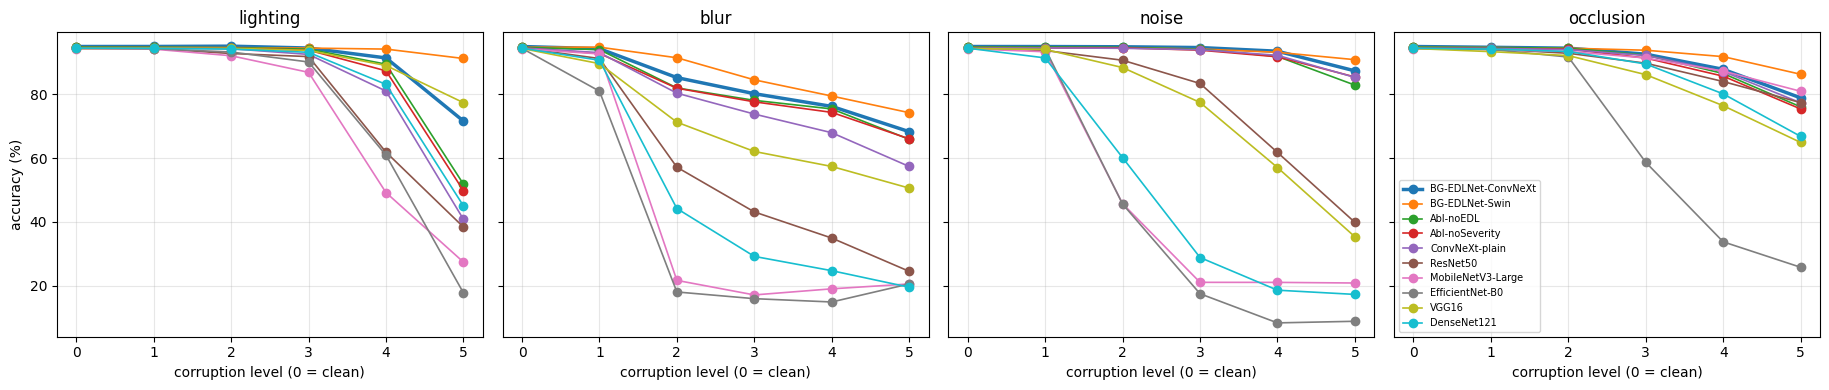

In [24]:
# =====================================================================================
# CELL 8.2 | STEP 5/8 — Robustness curves: accuracy vs corruption level for every model
# =====================================================================================
rob_rows = [dict(model=r["model"], ctype=c, level=l, acc=a, unc=u) for r in RESULTS for (c, l), (a, u) in r["robust"].items()]
if rob_rows:
    ROB_DF = pd.DataFrame(rob_rows).groupby(["model", "ctype", "level"], as_index=False)[["acc", "unc"]].mean()
    ROB_DF.to_csv(os.path.join(CFG.REPORT_DIR, "robustness_by_type_level.csv"), index=False)

    print("=== Table 4: mean accuracy (%) over the 4 corruption types, by level (0 = clean) ===")
    avg_lvl = (ROB_DF.groupby(["model", "level"])["acc"].mean().unstack("level") * 100).reindex(MODEL_ORDER).round(2)
    avg_lvl["Retention @L5 (%)"] = (100 * avg_lvl[5] / avg_lvl[0]).round(1)
    print(avg_lvl.to_string())
    print("\nMean predictive uncertainty by level (should rise with corruption for evidential models):")
    print((ROB_DF.groupby(["model", "level"])["unc"].mean().unstack("level")).reindex(MODEL_ORDER).round(3).to_string())

    ctypes = list(CFG.CORRUPTIONS)
    fig, axes = plt.subplots(1, len(ctypes), figsize=(4.6 * len(ctypes), 4), sharey=True)
    for ax, ct in zip(np.atleast_1d(axes), ctypes):
        for mdl in MODEL_ORDER:
            d = ROB_DF[(ROB_DF.model == mdl) & (ROB_DF.ctype == ct)].sort_values("level")
            ax.plot(d.level, 100 * d.acc, marker="o", lw=2.5 if mdl == CFG.PROPOSED else 1.2, label=mdl)
        ax.set_title(ct); ax.set_xlabel("corruption level (0 = clean)"); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel("accuracy (%)")
    np.atleast_1d(axes)[-1].legend(fontsize=7, loc="lower left")
    plt.tight_layout(); plt.savefig(os.path.join(CFG.REPORT_DIR, "robustness_curves.png"), dpi=150); plt.show()

=== Table 5: calibration + fixed expert-refer rule (u > 0.3 or max-prob < 0.6) ===
                                ECE            Brier  Refer rate (%)  Acc. retained (%)  Acc. referred (%)
Model                                                                                                     
BG-EDLNet-ConvNeXt  0.1221 ± 0.0139  0.0864 ± 0.0142            9.73              99.49              53.80
BG-EDLNet-Swin      0.1176 ± 0.0134  0.0830 ± 0.0099           10.45              99.86              51.57
Abl-noEDL           0.0460 ± 0.0105  0.0619 ± 0.0080            9.98              99.50              51.96
Abl-noSeverity      0.1040 ± 0.0544  0.0843 ± 0.0138           10.51              99.70              49.69
ConvNeXt-plain      0.0260 ± 0.0109  0.0620 ± 0.0108            9.08              98.97              55.91
ResNet50            0.0579 ± 0.0106  0.0690 ± 0.0109           11.17              99.32              54.84
MobileNetV3-Large   0.0438 ± 0.0079  0.0639 ± 0.0126         

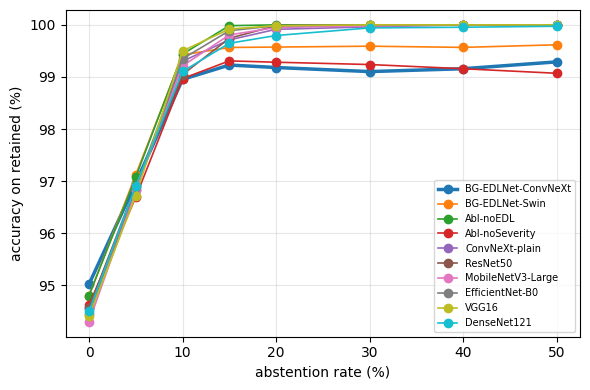

In [25]:
# =====================================================================================
# CELL 8.3 | STEP 3/8 — Calibration (ECE, Brier) and abstention: abstention-rate vs accuracy, expert-refer rule
# =====================================================================================
CAL = ci_table({"ECE": "ece", "Brier": "brier"}, pct=False)
CAL["Refer rate (%)"] = (100 * RUNS_DF.groupby("model")["abst_rate"].mean()).reindex(CAL.index).round(2)
CAL["Acc. retained (%)"] = (100 * RUNS_DF.groupby("model")["acc_retained"].mean()).reindex(CAL.index).round(2)
CAL["Acc. referred (%)"] = (100 * RUNS_DF.groupby("model")["acc_referred"].mean()).reindex(CAL.index).round(2)
print(f"=== Table 5: calibration + fixed expert-refer rule (u > {CFG.ABSTAIN_UNC} or max-prob < {CFG.ABSTAIN_CONF}) ===")
print(CAL.to_string()); CAL.to_csv(os.path.join(CFG.REPORT_DIR, "table5_calibration.csv"))

curves = {m: np.mean([r["abst_curve"] for r in RESULTS if r["model"] == m], axis=0) for m in MODEL_ORDER}
ABST_TAB = pd.DataFrame({m: 100 * c for m, c in curves.items()}, index=[f"{int(100 * r)}%" for r in CFG.ABSTAIN_RATES]).T.round(2)
print("\n=== Table 6: accuracy (%) on retained samples when the most-uncertain X% are referred to an expert ===")
print(ABST_TAB.to_string()); ABST_TAB.to_csv(os.path.join(CFG.REPORT_DIR, "table6_abstention_curve.csv"))

plt.figure(figsize=(6, 4))
for m, c in curves.items():
    plt.plot(100 * np.array(CFG.ABSTAIN_RATES), 100 * c, marker="o", lw=2.5 if m == CFG.PROPOSED else 1.2, label=m)
plt.xlabel("abstention rate (%)"); plt.ylabel("accuracy on retained (%)"); plt.grid(alpha=0.3); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(CFG.REPORT_DIR, "abstention_curve.png"), dpi=150); plt.show()

In [26]:
# =====================================================================================
# CELL 8.4 | STEP 6/8 — XAI faithfulness table + confusion matrix of the proposed model
# =====================================================================================
if CFG.RUN_XAI:
    XAI_TAB = ci_table({"Insertion AUC ↑": "ins_auc", "Deletion AUC ↓": "del_auc"}, pct=False)
    if RUNS_DF["pointing"].notna().any():
        XAI_TAB["Pointing Game (%)"] = ci_table({"p": "pointing"}, pct=True)["p"]
    else:
        print("(No ground-truth lesion masks supplied -> Pointing Game skipped; reporting Insertion/Deletion AUC only.)")
    print("=== Table 7: Grad-CAM faithfulness ===");  print(XAI_TAB.to_string())
    XAI_TAB.to_csv(os.path.join(CFG.REPORT_DIR, "table7_xai.csv"))

if CFG.PROPOSED in MODEL_ORDER:
    cm_sum = sum(r["cm"] for r in RESULTS if r["model"] == CFG.PROPOSED)
    cm_df = pd.DataFrame(cm_sum, index=[f"true:{c}" for c in CFG.CLASSES], columns=[f"pred:{c}" for c in CFG.CLASSES])
    print(f"\n=== Confusion matrix of {CFG.PROPOSED} (summed over all folds and seeds) ===")
    print(cm_df.to_string())
    print("Per-class recall (%):", dict(zip(CFG.CLASSES, (100 * np.diag(cm_sum) / cm_sum.sum(1)).round(2))))
    cm_df.to_csv(os.path.join(CFG.REPORT_DIR, "confusion_matrix_proposed.csv"))
print("\nAll tables and figures saved to:", CFG.REPORT_DIR)

(No ground-truth lesion masks supplied -> Pointing Game skipped; reporting Insertion/Deletion AUC only.)
=== Table 7: Grad-CAM faithfulness ===
                    Insertion AUC ↑   Deletion AUC ↓
Model                                               
BG-EDLNet-ConvNeXt  0.8062 ± 0.0512  0.4941 ± 0.0580
BG-EDLNet-Swin      0.7644 ± 0.0191  0.6127 ± 0.0374
Abl-noEDL           0.8973 ± 0.0265  0.4788 ± 0.0636
Abl-noSeverity      0.7597 ± 0.0525  0.6053 ± 0.1416
ConvNeXt-plain      0.9034 ± 0.0357  0.4985 ± 0.0888
ResNet50            0.7403 ± 0.0327  0.4305 ± 0.0636
MobileNetV3-Large   0.2556 ± 0.0210  0.2414 ± 0.0448
EfficientNet-B0     0.2962 ± 0.0635  0.2613 ± 0.0366
VGG16               0.9107 ± 0.0639  0.4682 ± 0.0754
DenseNet121         0.8282 ± 0.0296  0.4727 ± 0.0502

=== Confusion matrix of BG-EDLNet-ConvNeXt (summed over all folds and seeds) ===
                    pred:Anthracnose  pred:Downey mildew  pred:Fresh leaf  pred:Fusarium wilt  pred:Mosaic virus
true:Anthracnose         